# 05 — L1: número de pronto-atendimentos e população das capitais

## Pergunta

Capitais mais populosas têm um número de pronto-atendimentos proporcional à população?

$$N_c=C P_c^\beta, \qquad \log_{10}N_c=c+\beta\log_{10}P_c.$$

- **β = 1:** proporcionalidade; unidades por morador constantes no modelo.
- **β < 1:** relação sublinear; capitais maiores têm menor número de unidades por morador no ajuste.
- **β > 1:** relação superlinear.

Esta é uma comparação **entre capitais**, diferente da L2, que compara áreas de atendimento. A versão principal conta unidades SUS, e todos os estabelecimentos são a robustez.

Usamos OLS log-log e **2.000 reamostragens das capitais**, com semente 42, como na exploração anterior. Não acrescentamos recortes de concentração urbana ou outros modelos opcionais.

Contamos estabelecimentos, não nós da rede: as duas unidades compartilhadas de Porto Alegre continuam sendo dois estabelecimentos. A correção de setores não altera essas contagens municipais.


In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display, Markdown

RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "PLANO.md").exists())
PROC = RAIZ / "dados" / "processados"
SAIDA = PROC / "analises" / "L1"
FIG = RAIZ / "figuras" / "L1"
SAIDA.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(RAIZ / "scripts"))
import estilo
estilo.aplicar()
N_BOOT, SEMENTE = 2000, 42
capitais = pd.read_csv(PROC / "capitais_resumo.csv")
unidades = pd.read_csv(PROC / "pa_capitais_corrigido.csv", dtype={"CO_CNES": str})
assert len(capitais) == 27 and not capitais.municipio.duplicated().any()

# Conferir as contagens contra o cadastro, sem usar áreas de atendimento.
for coluna, mascara in [("n_pa", np.ones(len(unidades), dtype=bool)),
                         ("n_pa_sus", unidades.atende_sus)]:
    contagem = unidades.loc[mascara].groupby("municipio").size()
    conferida = capitais.municipio.map(contagem).fillna(0).astype(int)
    np.testing.assert_array_equal(conferida.to_numpy(), capitais[coluna].to_numpy())
display(capitais[["municipio", "populacao_2022", "n_pa_sus", "n_pa"]])


,municipio,populacao_2022,n_pa_sus,n_pa
0,São Paulo - SP,11451999,56,64
1,Rio de Janeiro - RJ,6211223,31,38
2,Brasília - DF,2817381,13,14
3,Fortaleza - CE,2428708,12,13
4,Salvador - BA,2417678,20,21
5,Belo Horizonte - MG,2315560,9,11
6,Manaus - AM,2063689,10,11
7,Curitiba - PR,1773718,9,9
8,Recife - PE,1488920,5,6
9,Goiânia - GO,1437366,6,8


## 1. Zeros e amostra do ajuste

O logaritmo de zero não é definido. As capitais com zero unidades do recorte ficam fora da regressão, mas são listadas e permanecem na descrição dos dados.

**Zero no cadastro de tipo 73 não significa ausência de atendimento de urgência.** No caso de Aracaju, o plano registra que seus serviços de urgência estão classificados em outro tipo de estabelecimento. Não alteramos o recorte do CNES para incluir esses serviços.


In [2]:
amostras, exclusoes = {}, []
for versao, coluna in [("SUS", "n_pa_sus"), ("Todos", "n_pa")]:
    usa = capitais.loc[(capitais[coluna] > 0)&(capitais.populacao_2022 > 0)].copy()
    usa["n_unidades"] = usa[coluna]
    usa["versao"] = versao
    amostras[versao] = usa
    for _, capital in capitais.loc[capitais[coluna] == 0].iterrows():
        exclusoes.append({"versao":versao, "capital":capital.municipio, "motivo":"zero estabelecimentos do recorte"})
    usa.to_csv(SAIDA / f"capitais_{versao.lower()}.csv", index=False)
display(pd.DataFrame(exclusoes))
print("Capitais no ajuste:", {v:len(d) for v,d in amostras.items()})


,versao,capital,motivo
0,SUS,Aracaju - SE,zero estabelecimentos do recorte
1,Todos,Aracaju - SE,zero estabelecimentos do recorte


Capitais no ajuste: {'SUS': 26, 'Todos': 26}


## 2. Ajuste e bootstrap

Cada capital tem o mesmo peso no ajuste, independentemente de sua população. A regressão minimiza desvios quadráticos em logaritmo.

No bootstrap, sorteamos o mesmo número de capitais com reposição e repetimos o ajuste. Os percentis 2,5 e 97,5 dos expoentes formam o intervalo de 95%.

Se o intervalo inclui 1, os dados são compatíveis com proporcionalidade sob esse procedimento. Uma estimativa pontual abaixo de 1, sozinha, não basta para concluir que a relação é sublinear.


In [3]:
resultados, bootstraps = [], {}
for versao, dados in amostras.items():
    x, y = np.log10(dados.populacao_2022.to_numpy()), np.log10(dados.n_unidades.to_numpy())
    beta, c = np.polyfit(x, y, 1)
    previsao = c+beta*x
    r2 = 1-np.sum((y-previsao)**2)/np.sum((y-y.mean())**2)
    rng = np.random.default_rng(SEMENTE)
    coefs = []
    for _ in range(N_BOOT):
        indices = rng.integers(0,len(dados),len(dados))
        assert np.ptp(x[indices]) > 0, "Reamostragem degenerada: investigar."
        coefs.append(np.polyfit(x[indices], y[indices], 1))
    boot = pd.DataFrame(coefs,columns=["beta","c"])
    bootstraps[versao] = boot
    inferior, superior = np.percentile(boot.beta,[2.5,97.5])
    resultados.append({
        "versao":versao, "n_capitais":len(dados), "beta":beta, "c":c,
        "ic95_inferior":inferior, "ic95_superior":superior,
        "R2_loglog":r2, "n_bootstrap":len(boot), "semente":SEMENTE,
        "fator_N_populacao_dobra":2**beta,
        "inclui_proporcionalidade": bool(inferior <= 1 <= superior)
    })
    dados["log10_residuo"] = y-previsao
    np.testing.assert_allclose(dados.log10_residuo.mean(),0,atol=1e-10)
    dados.to_csv(SAIDA / f"capitais_{versao.lower()}.csv", index=False)
    boot.to_csv(SAIDA / f"bootstrap_{versao.lower()}.csv", index=False)

resultados = pd.DataFrame(resultados)
resultados.to_csv(SAIDA / "resultados_L1.csv", index=False)
display(resultados.set_index("versao").round(4))


,n_capitais,beta,c,ic95_inferior,ic95_superior,R2_loglog,n_bootstrap,semente,fator_N_populacao_dobra,inclui_proporcionalidade
versao,,,,,,,,,,
SUS,26,0.8702,-4.4690,0.6925,1.0215,0.7951,2000,42,1.8279,True
Todos,26,0.8834,-4.5063,0.6949,1.0508,0.8022,2000,42,1.8447,True


## 3. Visualização

Cada ponto é uma capital. As linhas de referência β = 1 passam pelas médias dos logaritmos para facilitar a comparação de inclinações. A faixa sombreada é o intervalo bootstrap da reta média, não um intervalo de previsão para outra capital.

A figura inclui a versão SUS e a robustez. O recorte temporal combina população de 2022 com estabelecimentos cadastrados em 2026; não é uma análise de crescimento das cidades ao longo do tempo.


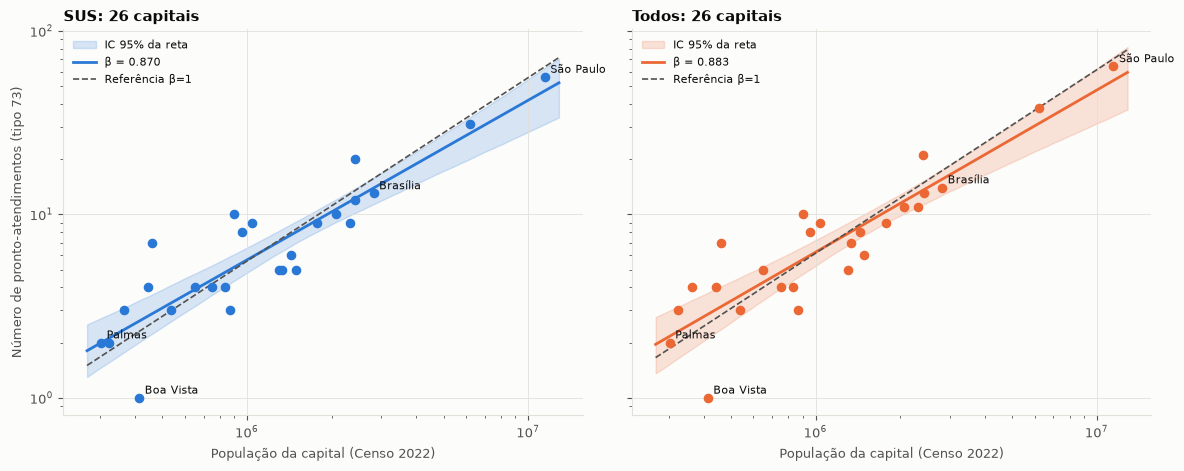

In [4]:
fig, eixos = plt.subplots(1,2,figsize=(12,4.8),sharex=True,sharey=True)
for ax, versao, cor in zip(eixos,["SUS","Todos"],[estilo.AZUL,estilo.LARANJA]):
    d = amostras[versao]
    r = resultados.loc[resultados.versao == versao].iloc[0]
    boot = bootstraps[versao]
    xslog = np.linspace(np.log10(d.populacao_2022.min())-.05,np.log10(d.populacao_2022.max())+.05,200)
    xs = 10**xslog
    previsoes = boot.c.to_numpy()[:,None]+boot.beta.to_numpy()[:,None]*xslog
    inferior,superior = 10**np.percentile(previsoes,[2.5,97.5],axis=0)
    ax.scatter(d.populacao_2022,d.n_unidades,color=cor,s=35,zorder=3)
    ax.fill_between(xs,inferior,superior,color=cor,alpha=.18,label="IC 95% da reta")
    ax.plot(xs,10**(r.c+r.beta*xslog),color=cor,label=f"β = {r.beta:.3f}")
    mx,my = np.log10(d.populacao_2022).mean(),np.log10(d.n_unidades).mean()
    ax.plot(xs,10**(my+xslog-mx),"--",color=estilo.TEXTO_2,linewidth=1.2,label="Referência β=1")
    for _,capital in d.iterrows():
        if capital.municipio.split(" - ")[0] in ["São Paulo","Boa Vista","Palmas","Brasília"]:
            ax.annotate(capital.municipio.split(" - ")[0],(capital.populacao_2022,capital.n_unidades),
                        xytext=(4,3),textcoords="offset points",fontsize=8)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("População da capital (Censo 2022)")
    ax.set_title(f"{versao}: {len(d)} capitais")
    ax.legend(fontsize=8,loc="upper left")
eixos[0].set_ylabel("Número de pronto-atendimentos (tipo 73)")
fig.tight_layout()
for extensao in ["png","pdf"]:
    fig.savefig(FIG / f"01_lei_escala.{extensao}")
plt.show()


## 4. Resultado em palavras e limites

O texto abaixo usa o intervalo estimado para evitar confundir a posição da estimativa com uma diferença sustentada pelo procedimento de incerteza.


In [5]:
textos = []
for _,r in resultados.iterrows():
    leitura = (
        "O intervalo inclui 1: não rejeitamos proporcionalidade segundo este procedimento."
        if r.inclui_proporcionalidade else
        "O intervalo está abaixo de 1: o ajuste indica relação sublinear segundo este procedimento."
        if r.ic95_superior < 1 else
        "O intervalo está acima de 1: o ajuste indica relação superlinear segundo este procedimento."
    )
    textos.append(
        f'**{r.versao}: β={r.beta:.3f}, IC 95% [{r.ic95_inferior:.3f}; {r.ic95_superior:.3f}].** '
        f'{leitura} A comparação usa {int(r.n_capitais)} capitais; dobrar a população '
        f'corresponde a multiplicar o número previsto de unidades por {r.fator_N_populacao_dobra:.2f}.'
    )
texto = "\n\n".join(textos)
display(Markdown(texto))
(SAIDA / "interpretacao_L1.md").write_text(texto+"\n",encoding="utf-8")


**SUS: β=0.870, IC 95% [0.693; 1.021].** O intervalo inclui 1: não rejeitamos proporcionalidade segundo este procedimento. A comparação usa 26 capitais; dobrar a população corresponde a multiplicar o número previsto de unidades por 1.83.

**Todos: β=0.883, IC 95% [0.695; 1.051].** O intervalo inclui 1: não rejeitamos proporcionalidade segundo este procedimento. A comparação usa 26 capitais; dobrar a população corresponde a multiplicar o número previsto de unidades por 1.84.

479

### Limitações e fontes do curso

São apenas 26 observações, com intervalo de incerteza largo. O limite municipal não corresponde necessariamente à região metropolitana, e o resultado pode mudar com a definição de cidade. População e cadastro não são do mesmo ano. O tipo 73 é heterogêneo e a capacidade dos estabelecimentos não é considerada.

- Bettencourt et al. (2007), *Growth, innovation, scaling, and the pace of life in cities*: Aula 4, slide 22, e Aula 5, slide 15.
- Melo et al. (2014), *Statistical Signs of Social Influence on Suicides*: OLS e bootstrap no estudo de leis de escala; PDF em `Bibliografia/`. Aqui reamostramos diretamente capitais e não usamos a suavização do artigo.
- Arcaute et al. (2015), *Constructing cities, deconstructing scaling laws*: efeito da definição de cidade; PDF em `Bibliografia/`.
- [PLANO.md](../PLANO.md), seção 7.4, e [planejamento.md](../planejamento.md), seção 4.

Saídas em `dados/processados/analises/L1/` e `figuras/L1/`. Todos os cálculos e o gráfico estão neste notebook.
